<a href="https://colab.research.google.com/github/saraeudora/Pytorch-Tutorial/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
##import MINIST images
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
%matplotlib inline


In [ ]:
#convert MNIST image file into tensor of 4D (# of images, height, width and color channel)
transform = transforms.ToTensor()


In [ ]:
#train data
train_data = datasets.MNIST(root='/cnn_data', train=True, download=True, transform=transform)


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.85MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 126kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.21MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.45MB/s]


In [ ]:
#test data
test_data = datasets.MNIST(root='/cnn_data', train=False, download=True, transform=transform)

In [ ]:
train_data

Dataset MNIST
    Number of datapoints: 60000
    Root location: /cnn_data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [ ]:
test_data

Dataset MNIST
    Number of datapoints: 10000
    Root location: /cnn_data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [ ]:
# create a small batch size for images
train_loader  = DataLoader(train_data, batch_size=10, shuffle=True)
test_loader = DataLoader(test_data, batch_size=10, shuffle=False)



In [ ]:
#define our CNN model
#describe convolutional layer and wahts it's doing (2 convolutional layer)
conv1 = nn.Conv2d(1, 6, 3, 1)
conv2 = nn.Conv2d(6, 16, 3, 1)



In [ ]:
#grab 1 MNIST image
for i, (X_Train, y_train) in enumerate(train_data):
  break

In [ ]:
X_Train.shape

torch.Size([1, 28, 28])

In [ ]:
x = X_Train.view(1,1,28,28)

In [ ]:
#perform our first convolution
x = F.relu(conv1(x)) #rectified linear unit for our activation function




In [ ]:
# 1 single image, 6 is the filters we asked for, 26x26
x.shape

torch.Size([1, 6, 26, 26])

In [ ]:
# pass thre pooling layer
x = F.max_pool2d(x,2,2) #kernel of 2 and stride of 2


In [ ]:
x.shape # 26 / 2 = 13

torch.Size([1, 6, 13, 13])

In [ ]:
#Do our second convolutional layer
x = F.relu(conv2(x))

In [ ]:
x.shape # again we didnt set padding so we lose 2 pixel around the outside of the image

torch.Size([1, 16, 11, 11])

In [ ]:
#pooling layer
x = F.max_pool2d(x,2,2)


In [ ]:
x.shape # 11 / 2 = 5.5 but we have to round down because you cant invent data to round up

torch.Size([1, 16, 5, 5])

In [ ]:
# Model Class
class ConvololutionalNework(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(1, 6, 3, 1)
    self.conv2 = nn.Conv2d(6, 16, 3, 1)
    # we need a fully connected layer
    self.fc1 = nn.Linear(5*5*16, 120)
    self.fc2 = nn.Linear(120, 84)
    self.fc3 = nn.Linear(84, 10)

  def forward(self, X):
    X = F.relu(self.conv1(X))
    X = F.max_pool2d(X,2,2)
    #second pass
    X = F.relu(self.conv2(X))
    X = F.max_pool2d(X,2,2)

    #re-View to flatten it out
    X = X.view(-1, 16*5*5) #negative one so that we can vary the batch size

    #fully connected Layer
    X = F.relu(self.fc1(X))
    X = F.relu(self.fc2(X))
    X = self.fc3(X)
    return F.log_softmax(X, dim=1)





In [ ]:
# Create and instance of our model
torch.manual_seed(41)
model = ConvololutionalNework()
model


ConvololutionalNework(
  (conv1): Conv2d(1, 6, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [ ]:
# Loss function Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) #smaller the lr the longer its gonna take to train



In [ ]:

# TRAIN AND TEST CNN MODEL
import time
start_time = time.time()

# Create variables to track things
epochs = 5
train_losses = []
test_losses = []
train_correct = []
test_correct = []

# For loop of epochs
for i in range(epochs):
    trn_corr = 0
    tst_corr = 0

    # Train
    for b, (X_train, y_train) in enumerate(train_loader):
        b += 1  # starts our batches at 1

        y_pred = model(X_train)  # get predicted values
        loss = criterion(y_pred, y_train)  # compare predictions with correct answers

        predicted = torch.max(y_pred.data, 1)[1]
        batch_corr = (predicted == y_train).sum()
        trn_corr += batch_corr  # keep track of correct predictions

        # Update our parameters
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Print out some results
        if b % 600 == 0:
            print(f'Epoch: {i} Batch: {b} Loss: {loss.item()}')

    train_losses.append(loss.item())
    train_correct.append(trn_corr.item())

    # Test
    with torch.no_grad():
        for b, (X_test, y_test) in enumerate(test_loader):
            y_val = model(X_test)
            loss = criterion(y_val, y_test)

            predicted = torch.max(y_val.data, 1)[1]
            tst_corr += (predicted == y_test).sum()

    test_losses.append(loss.item())
    test_correct.append(tst_corr.item())

current_time = time.time()
total = current_time - start_time
print(f'Training took: {total/60} minutes!')



Epoch: 0 Batch: 600 Loss: 0.0505208782851696
Epoch: 0 Batch: 1200 Loss: 0.0059844679199159145
Epoch: 0 Batch: 1800 Loss: 0.04089317470788956
Epoch: 0 Batch: 2400 Loss: 0.14491525292396545
Epoch: 0 Batch: 3000 Loss: 0.07276292145252228
Epoch: 0 Batch: 3600 Loss: 8.52169978315942e-05
Epoch: 0 Batch: 4200 Loss: 0.0002624420740175992
Epoch: 0 Batch: 4800 Loss: 0.0008155832183547318
Epoch: 0 Batch: 5400 Loss: 0.0035763015039265156
Epoch: 0 Batch: 6000 Loss: 0.0004282502341084182
Epoch: 1 Batch: 600 Loss: 0.019201355054974556
Epoch: 1 Batch: 1200 Loss: 0.009914401918649673
Epoch: 1 Batch: 1800 Loss: 0.0029185726307332516
Epoch: 1 Batch: 2400 Loss: 0.001361339702270925
Epoch: 1 Batch: 3000 Loss: 0.22159895300865173
Epoch: 1 Batch: 3600 Loss: 0.002131801564246416
Epoch: 1 Batch: 4200 Loss: 8.98157522897236e-05
Epoch: 1 Batch: 4800 Loss: 0.004659370519220829
Epoch: 1 Batch: 5400 Loss: 0.02360517717897892
Epoch: 1 Batch: 6000 Loss: 0.0010188050800934434
Epoch: 2 Batch: 600 Loss: 0.00061856181127

Graph CNN Result

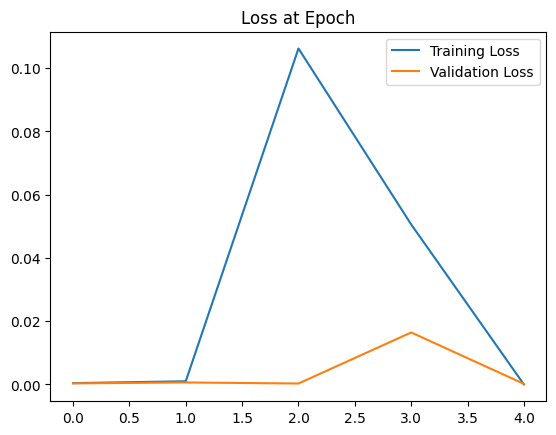

In [ ]:
# graph the loss at epoch
plt.plot(train_losses, label='Training Loss')
plt.plot(test_losses, label='Validation Loss')
plt.title("Loss at Epoch")
plt.legend()


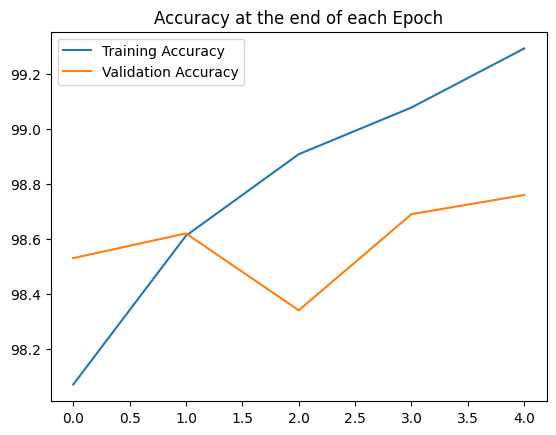

In [ ]:
# graph the accuracy at the end of each epoch
plt.plot([t/600 for t in train_correct], label='Training Accuracy')
plt.plot([t/100 for t in test_correct], label='Validation Accuracy')
plt.title("Accuracy at the end of each Epoch")
plt.legend()

In [ ]:
test_load_everything = DataLoader(test_data, batch_size=10000, shuffle=False)


In [ ]:
with torch.no_grad():
  correct = 0
  for i, (X_test, y_test) in enumerate(test_load_everything):
    y_val = model(X_test)
    predicted = torch.max(y_val.data, 1)[1]
    correct += (predicted == y_test).sum()
  print(f'Test Accuracy: {correct.item()/10000*100}')

Test Accuracy: 98.76


Send new image thru the model

In [ ]:
# grab an image
test_data[1978] # tensor with an image in it and at the end it shows the label


(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 

In [ ]:
#grab the data
test_data[4143][0]

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,

In [ ]:
#Reshape it
test_data[1978][0].reshape =(28,28)

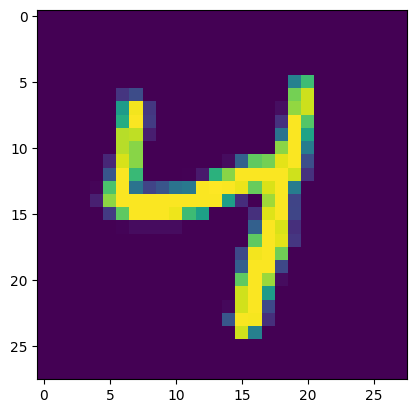

In [ ]:
plt.imshow(test_data[1978][0].reshape(28, 28))


In [ ]:
# PASS THE IMAGE THRU OUR MODEL
model.eval()
with torch.no_grad():
  new_prediction = model(test_data[1978][0].view(1,1,28,28))


In [ ]:
#check the new prediction
new_prediction

tensor([[-2.9655e+01, -2.3924e+01, -3.1812e+01, -4.3046e+01, -3.9339e-06,
         -2.2031e+01, -1.7585e+01, -2.4440e+01, -2.2605e+01, -1.2432e+01]])

In [ ]:
new_prediction.argmax()

tensor(4)